# 10. Методологический аудит

**Вся неделя уже просмотрена. Это диагностическое исследование, не новый holdout.**

Расчёты воспроизводятся командой `python methodology_audit.py`. Исторические модели не переобучаются и не заменяются. Сетка из 363 допустимых пар одинакова для двух целей; настройка использует прежний validation. Это расширенный baseline, но не равенство всех бюджетов.

Все новые стратегии начинают с 2 шардов и оплачивают разгон. Перегрузка — превышение условной мощности, не измеренный SLA. Полный разбор: METHODOLOGY_REVIEW.md.

In [1]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image
p=Path('results/methodology_audit')
display(json.loads((p/'selection.json').read_text()))
display(pd.read_csv(p/'comparison_common_start.csv'))

{'cost': {'up': 1.1, 'down': 0.85, 'candidates': 363},
 'safety': {'up': 0.95, 'down': 0.1, 'candidates': 363}}

,strategy,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,original_dqn,779.103437,632.0,120.632280,26.471158,46,32625,136.898674,3.291667,23
1,safety_dqn_exploratory,889.648951,854.0,9.609909,26.039042,2,2599,134.663934,4.447917,31
2,original_threshold,929.842189,908.0,15.936402,5.905787,4,4310,30.542463,4.729167,6
3,threshold_cost,941.590568,590.0,257.703827,93.886741,75,69696,485.546208,3.072917,74
4,threshold_safety,1136.391425,1121.0,10.615641,4.775785,3,2871,24.698526,5.838542,5
5,ramp_target_2,2607.020891,384.0,2223.020891,0.000000,189,601216,0.000000,2.000000,0
6,ramp_target_3,899.578518,576.0,322.044740,1.533778,73,87097,7.932110,3.000000,1
7,ramp_target_4,822.843049,767.0,53.251987,2.591061,14,14402,13.399976,3.994792,2
8,ramp_target_5,977.893382,957.0,17.507857,3.385525,4,4735,17.508634,4.984375,3
9,ramp_target_6,1160.668816,1146.0,10.615641,4.053175,3,2871,20.961467,5.968750,4


## Чувствительность
Переоценка фиксированных действий при других ценах не означает переобучение. В capacity_replay меняются наблюдения и действия замороженных политик. Ни один сценарий не объявляется измеренной реальной ценой или мощностью.

In [2]:
prices=pd.read_csv(p/'fixed_policy_repricing.csv')
display(prices[prices.migration_price.eq(4)].pivot(index='strategy',columns='overload_price',values='cost'))
display(pd.read_csv(p/'capacity_replay.csv'))

overload_price,0,5,20,40,80,160
strategy,,,,,,
original_dqn,658.471158,688.629228,779.103437,899.735717,1141.000276,1623.529394
original_threshold,913.905787,917.889887,929.842189,945.778591,977.651396,1041.397005
ramp_target_2,384.000000,939.755223,2607.020891,4830.041782,9276.083564,18168.167129
ramp_target_3,577.533778,658.044963,899.578518,1221.623258,1865.712739,3153.891700
ramp_target_4,769.591061,782.904058,822.843049,876.095036,982.599011,1195.606961
ramp_target_5,960.385525,964.762489,977.893382,995.401239,1030.416954,1100.448383
ramp_target_6,1150.053175,1152.707085,1160.668816,1171.284456,1192.515738,1234.978300
ramp_target_7,1338.577319,1340.979797,1348.187229,1357.797138,1377.016957,1415.456595
ramp_target_8,1526.035540,1528.438017,1535.645449,1545.255358,1564.475177,1602.914815


,strategy,capacity_factor,cost,server_cost,overload_cost,migration_cost,overloaded_slots,excess_requests,moved_mb,mean_shards,changes
0,original_dqn,0.5,2056.447815,1521.0,530.412276,5.035540,83,71725,26.041879,7.921875,6
1,safety_dqn_exploratory,0.5,2056.447815,1521.0,530.412276,5.035540,83,71725,26.041879,7.921875,6
2,original_threshold,0.5,2056.447815,1521.0,530.412276,5.035540,83,71725,26.041879,7.921875,6
3,threshold_cost,0.5,1965.061193,1361.0,585.017563,19.043630,107,79109,98.486348,7.088542,28
4,threshold_safety,0.5,2056.447815,1521.0,530.412276,5.035540,83,71725,26.041879,7.921875,6
...,...,...,...,...,...,...,...,...,...,...,...
67,ramp_target_4,2.0,769.591061,767.0,0.000000,2.591061,0,0,13.399976,3.994792,2
68,ramp_target_5,2.0,960.385525,957.0,0.000000,3.385525,0,0,17.508634,4.984375,3
69,ramp_target_6,2.0,1150.053175,1146.0,0.000000,4.053175,0,0,20.961467,5.968750,4
70,ramp_target_7,2.0,1338.577319,1334.0,0.000000,4.577319,0,0,23.672140,6.947917,5


## Различия дней
Нижняя граница перегрузок по доступным размещениям не учитывает предел скорости смены шардов и не является производственной невозможностью. Средний объём показывает, что пустой старт не равен постоянному росту базы всю неделю.

In [3]:
display(pd.read_csv(p/'daily_diagnostics.csv'))

,day,split,overload_slots_even_with_best_n,mean_live_mb,fixed4_overload_slots,requests
0,1,train,0,19.808901,0,1163841
1,2,train,0,21.123032,0,1248095
2,3,train,0,21.040552,17,1318934
3,4,train,0,21.879694,79,1476922
4,5,validation,64,21.064245,94,1813888
5,6,seen_test,0,22.119049,10,1360141
6,7,seen_test,0,21.752380,4,1313948


## Что делает сеть
Точки показывают фактические решения при наблюдавшихся состояниях. Действие зависит не только от загрузки; здесь остальные признаки не контролируются. График не доказывает причинность и не распространяется на неизвестные нагрузки.

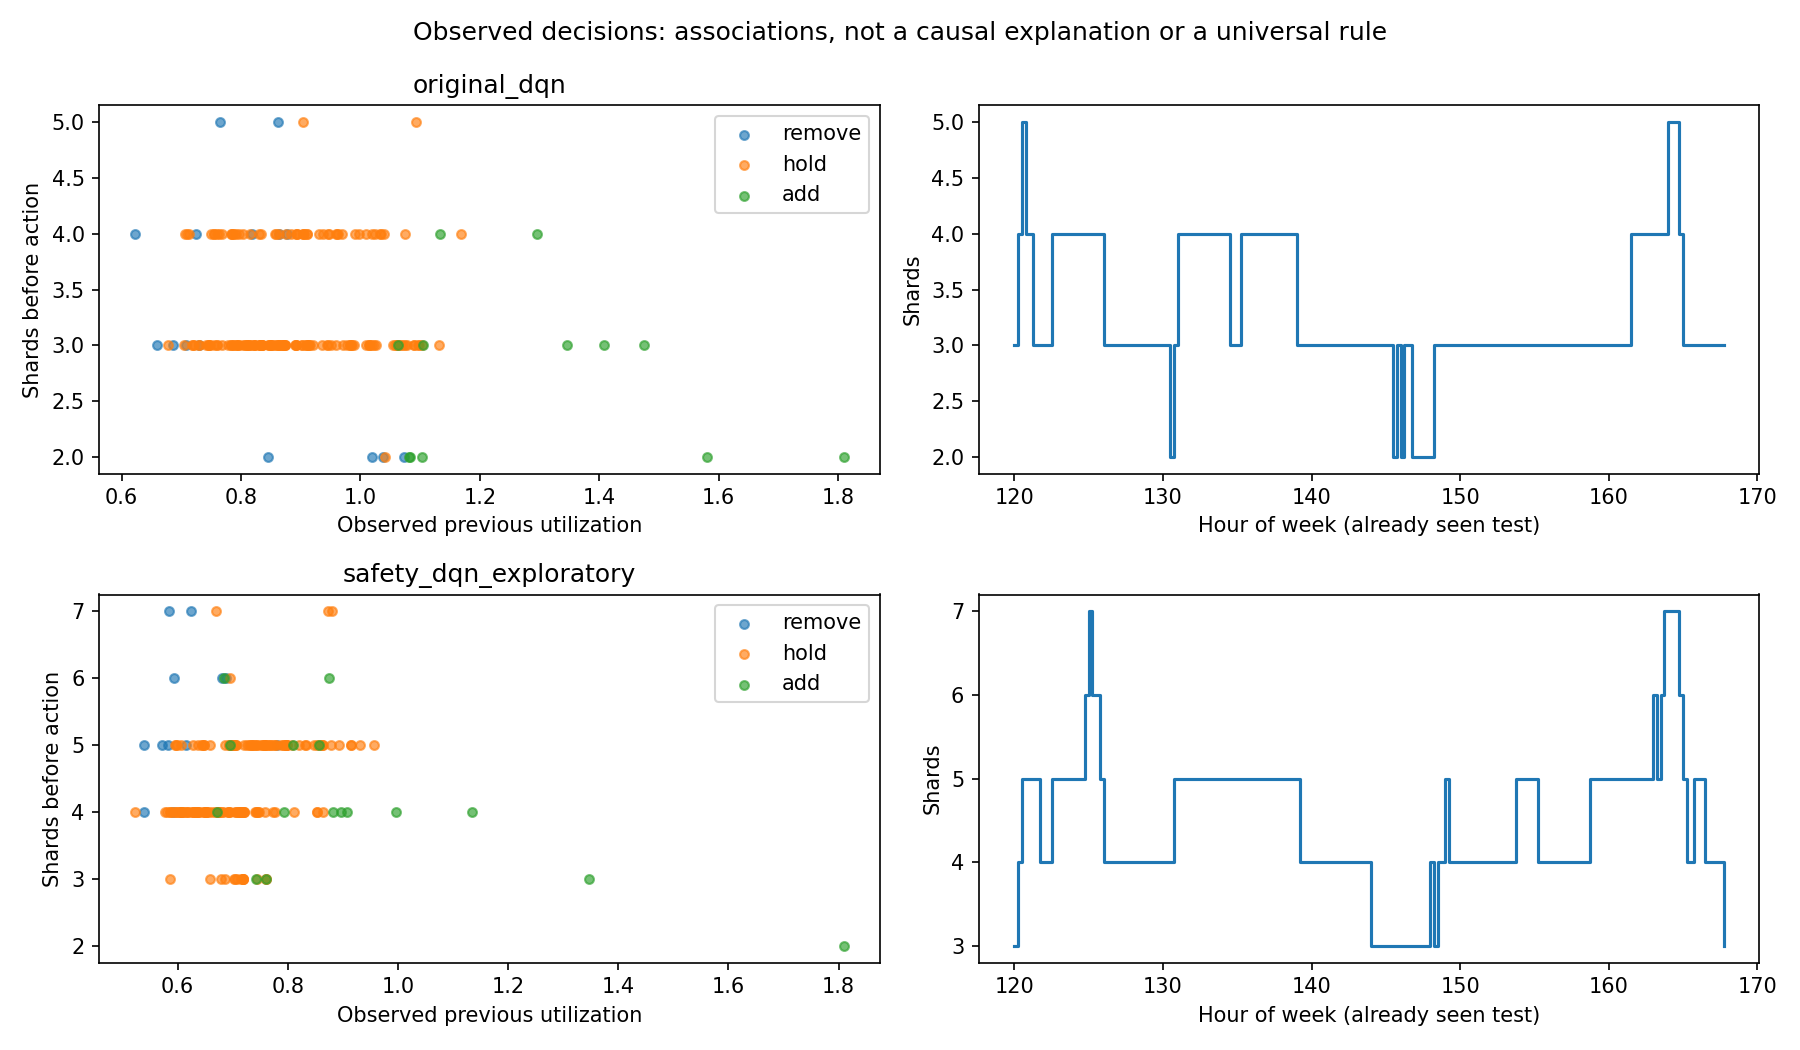

In [4]:
display(Image(filename=str(p/'policy_decisions.png')))

## Что остаётся открытым
Новый holdout, одинаковые представления Q/DQN, несколько validation-окон и физическая модель миграции ещё не реализованы. Нельзя заявлять независимое превосходство ИИ, реальные цены или гарантию нулевых перегрузок. Протокол следующего этапа — docs/NEXT_EXPERIMENT.md.